# The Karplus-Strong algorithm

O algoritmo de Karplus-Strong (KS) é uma laço de "*feedback*" digital simples com um "*buffer*" interno de $M$ amostras:
- O buffer é preenchido com um conjunto de valores iniciais.
- O laço, ao ser executado, produz um sinal de saída arbitráriamente longo.

Embora elementar, o laço KS pode ser utilizado para sintetizar sons musicais interessantes, como veremos neste Notebook.

Comecemos com uma implementação básica do laço KS (ou *malha* KS):

In [1]:
def KS_1(x, N):
    ''' 
    Cria um sinal com o algoritmo Karplus-Strong
        
    x : Sinal de entrada
    N : Tamanho do sinal (em número de amostras)
    '''
    
    # Dado o buffer initial x, producir uma saída de N-amostras
    # pela concatenação de cópias idênticas do buffer
    y = x
    
    while len(y) < N:
        # Continuar anexando até atingir (ou exceder) o comprimento requisitado
        y = np.append(y, x)
    
    # Limpar o excesso
    y = y[0:N]  # exatamente N amostras
    
    return y

Vamos a experimentar!
Mas, por mais impacientes que sejamos, ainda precisamos arrumar alguns detalhes.

Primeiro, precisamos incluir as bibliotecas Python necessárias:

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import os
import sys
sys.path.append('../../')
from lib.myPlotLib import *
from lib.myAudioProcessingLib import * # <- A nossa biblioteca de processamento de áudio

In [4]:
%matplotlib inline

In [5]:
import os
plt.rcParams['figure.figsize'] = (14, 4)

AUDIO_PATH = '../../sounds'   # Pasta de arquivos de som (corrigido)
MIDI_PATH  = '../../midi'     # Pasta de arquivos MIDI (sem uso ativo)


Depois, dado que estamos trabalhando com áudio, precisams definir o "relógio" interno do sistema, também conhecido como taxa de amostragem (*sampling rate*)

In [6]:
fs = 16000 # 16 KHz

Com esta taxa de amostragem, como o período do sinal gerado é igual ao comprimento do buffer inicial, poderemos calcular a frequência fundamental do som resultante.

Por exemplo, se iniciamos o algoritmo KS com um vetor de 50 valores, o buffer inicial caberá $16000 / 50 = 320$ vezes em um segundo de amostras.
Em outras palavras, a frequência resultante será de $320$Hz, o que corresponde aproximadamente à nota $E4$ em um piano (em notação de ''*[cifras](https://pt.wikipedia.org/wiki/Cifra_(m%C3%BAsica)#Regra_de_forma%C3%A7%C3%A3o)*'').

Perceba que nós ainda não falamos sobre o que usar como valores iniciais para o buffer.
Bem, o mais legal do KS é que podemos usar praticamente qualquer coisa que quisermos.
Na verdade, usar valores aleatórios lhe dará um som bom.
Como prova, considere este conjunto de dados inicial:

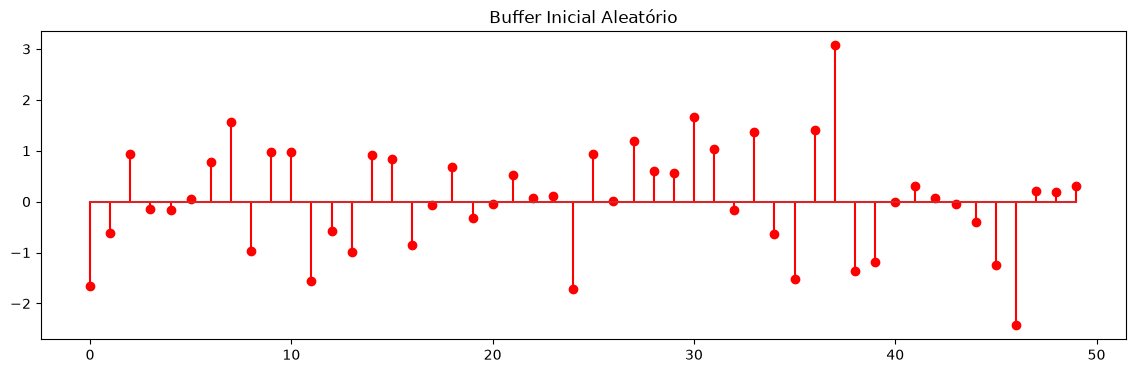

In [7]:
x = np.random.randn(50) # Sinal aleatorio inicial (ruido branco)

fig, ax = plt.subplots()
ax.stem(x, 'r')
plt.title('Buffer Inicial Aleatório')
plt.show()


Agora, vamos gerar um *clipe* de áudio de 2 segundos:

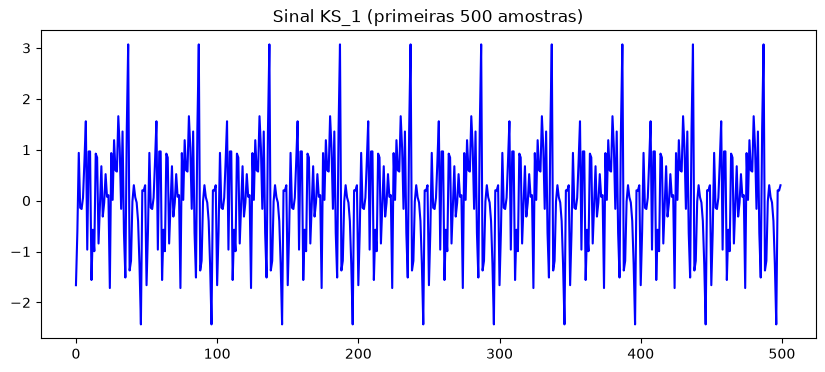

In [8]:
y = KS_1(x, 2*fs) # 2 segundos de áudio

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(y[0:500], 'b')
plt.title('Sinal KS_1 (primeiras 500 amostras)')
plt.show()


In [9]:
play(y, fs)

In [10]:
# Vamos tocar uma oitava abaixo: dobrando o comprimento do buffer inicial
x = np.random.randn(100) # Dobro do tamanho -> Metade da frequência (Oitava abaixo)
y = KS_1(x, 2*fs)

from IPython.display import Audio
Audio(data=y, rate=fs)


## Perguntas
1. Qual distribuição de probabilidade segue o sinal de entrada $x[n]$?
2. E se mudar de distribuição, o que acontece com o sinal de saída $y[n]$?

Mostre as saídas de áudio para distribuições diferentes na entrada

In [11]:
# 1. O sinal de entrada inicial `x[n] = np.random.randn(50)` segue uma distribuição **Normal (Gaussiana)**, $\mathcal{N}(0, 1)$, o que equivale a ruído branco térmico.
# 2. Se mudarmos para uma distribuição Uniforme `np.random.uniform(-1, 1, 50)`, a frequência fundamental do som gerado NÃO muda, pois ela depende exclusivamente do tamanho do buffer ($M=50$).
# O que muda é a percepção do timbre inicial (o 'ataque' da nota), pois diferentes distribuições de ruído injetam diferentes envelopes espectrais de energia na corda.

import numpy as np
from IPython.display import Audio, display

x_gauss = np.random.randn(50)
x_unif  = np.random.uniform(-1, 1, 50)

y_gauss = KS_1(x_gauss, 2*fs)
y_unif  = KS_1(x_unif, 2*fs)

print('Áudio com Ruído Gaussiano:')
display(Audio(data=y_gauss, rate=fs))

print('Áudio com Ruído Uniforme (pode soar ligeiramente mais áspero/metálico no ataque):')
display(Audio(data=y_unif, rate=fs))


Áudio com Ruído Gaussiano:


Áudio com Ruído Uniforme (pode soar ligeiramente mais áspero/metálico no ataque):


OK, então o algoritmo K-S funciona! Do ponto de vista do processamento de sinais, podemos descrever o sistema com o seguinte diagrama de blocos (desconsidere o fator "$\alpha$" por um momento)

<img src="./figures/ks.png" alt="" width="600"/>

A saída pode ser expressa como
$$
y[n] = x[n] + y[n - M]
$$

Assumindo que a entrada é o seguinte sinal de suporte finito
$$
x[n] = \begin{cases}
    0 & \mbox{for $n < 0$} \\
    b_n & \mbox{for $0 \le n < M$} \\
    0 & \mbox{for $n \ge M$}
  \end{cases}
$$

Implementemos o algoritmo KS como um laço de processamento de sinais!

In [12]:
def KS_2(x, N):
    ''' 
    Cria um sinal com o algoritmo Karplus-Strong
    
    x : Sinal de entrada
    N : Tamanho do sinal (em número de amostras)
    '''
    
    # Comprimento da entrada
    M = len(x)
    # Preparando a saída
    y = np.zeros(N)
    
    # Esta NAO é um implementação eficiente, porém ela mostra o princípio geral
    # Assumimos condições iniciais zeradas (y[n] = 0 para n < 0)
    for n in range(0, N):
        y[n] = (x[n] if n < M else 0) + (y[n-M] if n-M >= 0 else 0)
        
    return y

In [13]:
# Deveria funcionar (ainda) ...
x = np.random.randn(50)
y = KS_2(x, 2*fs)

play(y, fs)

Observando o diagrama de blocos, podemos visualizar uma modificação simples que adiciona muito realismo ao som:
- Definindo $\alpha$ para um valor próximo, mas menor que um, podemos introduzir um *decaimento* na nota, o que irá produzir sons parecidos aos de um **violão**!

$$
\Large
    y[n] = x[n] + {\color{red}\alpha} y[n - M]
$$

In [14]:
def KS_3(x, N, alpha=0.99):
    ''' 
    Cria um sinal com o algoritmo Karplus-Strong
        
    x     : Sinal de entrada
    N     : Tamanho do sinal (em número de amostras)
    alpha : Fator de decaimento
    '''
    
    M = len(x)
    y = np.zeros(N)
    
    for n in range(0, N):
        y[n] = (x[n] if n < M else 0) + alpha * (y[n-M] if n-M >= 0 else 0)
    
    return y

Se agora plotamos a saída KS resultante, podemos visualizar o "*envelope do decaimento*":

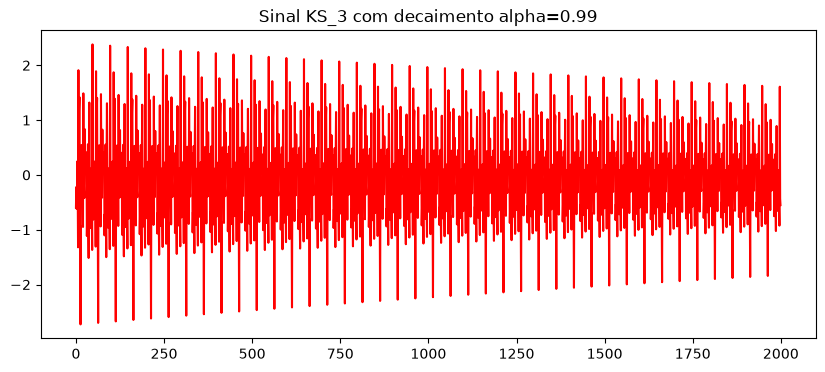

In [15]:
alpha = 0.99
y = KS_3(x, int(2*fs), alpha)

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(y[0:2000], 'r')
plt.title('Sinal KS_3 com decaimento alpha=0.99')
plt.show()

In [16]:
play(y, fs)

### Variação: o Karplus-Strong original (1983), com média

O artigo original do Karplus-Strong faz mais que atenuar: a cada volta, tira a **média de duas amostras vizinhas**:

$$
y[n] = \alpha\,\frac{y[n-M] + y[n-M-1]}{2}
$$

A média é um filtro **passa-baixas**: os harmônicos agudos morrem mais rápido que a fundamental, e o som fica mais
parecido com uma corda real. Como a média atrasa meia amostra, a nota sai em $f_s/(M + 0{,}5)$:
com $M = 50$, **316,8 Hz** em vez de 320 Hz.

In [17]:
def KS_media(x, N, alpha=0.99):
    '''
    Karplus-Strong original (1983): atenuacao + media de duas amostras vizinhas

    x     : Sinal de entrada (buffer inicial)
    N     : Tamanho do sinal (em numero de amostras)
    alpha : Fator de decaimento
    '''
    y = list(x)
    M = len(x)
    for i in range(M, N):
        y.append(alpha * 0.5 * (y[i - M] + y[i - M - 1]))
    return np.array(y)

y_media = KS_media(x, int(2*fs), 0.99)
print('KS_3 (formula do slide):')
display(Audio(data=KS_3(x, int(2*fs), 0.99), rate=fs))
print('KS_media (original, com passa-baixas): som mais "macio", agudos somem antes')
display(Audio(data=y_media, rate=fs))

KS_3 (formula do slide):


KS_media (original, com passa-baixas): som mais "macio", agudos somem antes


### 2. Que efeito produz o parâmetro $\alpha$ na saída?
Apresente as saídas de áudio para diferentes valores de $\alpha$

In [18]:
# O parâmetro alfa atua como o **fator de amortecimento (damping)** ou decaimento da corda.
# Matematicamente, ele simula a perda de energia por atrito e irradiação acústica a cada ciclo da onda.
# - alfa próximo de 1 (ex: 0.99): Decaimento longo, simula corda solta vibrando livremente.
# - alfa menor (ex: 0.85): Decaimento rápido, simula corda abafada (palm mute) ou material com alta absorção.

y_longo = KS_3(x_gauss, int(2*fs), alpha=0.99)
y_curto = KS_3(x_gauss, int(2*fs), alpha=0.85)

print('Decaimento LONGO (alfa = 0.99):')
display(Audio(data=y_longo, rate=fs))

print('Decaimento CURTO (alfa = 0.85):')
display(Audio(data=y_curto, rate=fs))


Decaimento LONGO (alfa = 0.99):


Decaimento CURTO (alfa = 0.85):


Há apenas um último detalhe.
Considere a saída de um laço KS *amortecido*.
Toda vez que o buffer inicial passa pelo laço, ele é multiplicado por $\alpha$ de forma que podemos escrever
$$
  y[n] = \alpha^{\lfloor n/M \rfloor} x[n \mod M]
$$
(pense sobre isto, até que faça sentido).

Isso significaque o envelope de decaimento depende de ambos $\alpha$ *e* $M$.
Em outras palavras, quanto mais alto o tom da nota, mais rápido é o decaimento. Por exemplo:

In [19]:
# Nota mais GRAVE: buffer de M = 50 amostras -> 16000/50 = 320 Hz
x50 = np.random.randn(50)
y50 = KS_3(x50, int(2*fs), 0.99)

print(f'M = 50 -> {fs/50:.0f} Hz; apos 1 s sobra 0.99^{fs//50} = {0.99**(fs/50):.4f} da amplitude')
Audio(data=y50, rate=fs)

M = 50 -> 320 Hz; apos 1 s sobra 0.99^320 = 0.0401 da amplitude


In [20]:
# Nota mais AGUDA: buffer de M = 25 amostras -> 16000/25 = 640 Hz (uma oitava acima)
# O alpha age uma vez por PERIODO, e a nota aguda tem o dobro de periodos por segundo
x25 = np.random.randn(25)
y25 = KS_3(x25, int(2*fs), 0.99)

print(f'M = 25 -> {fs/25:.0f} Hz; apos 1 s sobra 0.99^{fs//25} = {0.99**(fs/25):.4f} da amplitude')
Audio(data=y25, rate=fs)

M = 25 -> 640 Hz; apos 1 s sobra 0.99^640 = 0.0016 da amplitude


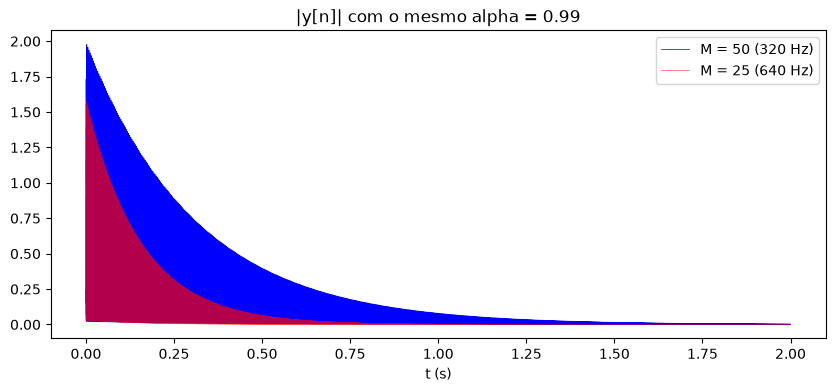

In [21]:
# Os dois envelopes lado a lado: a nota aguda morre bem mais rapido
t = np.arange(len(y50)) / fs
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, np.abs(y50), 'b', linewidth=0.5, label='M = 50 (320 Hz)')
ax.plot(t, np.abs(y25), 'r', linewidth=0.5, alpha=0.7, label='M = 25 (640 Hz)')
ax.set_xlabel('t (s)')
ax.set_title('|y[n]| com o mesmo alpha = 0.99')
ax.legend()
plt.show()

Isso não é bom!
Portanto, precisamos compensá-lo para que, se $\alpha$ for o mesmo, a taxa de decaimento seja a mesma.

Isso nos leva à nossa última implementação do algoritmo KS:

In [22]:
def KS(x, N, alpha=0.99, buff_size=50):
    ''' 
    Cria um sinal com o algoritmo Karplus-Strong
        
        x         : Sinal de entrada
        N         : Tamanho do sinal (em número de amostras)
        alpha     : Fator de decaimento
        buff_size : Tamanho do buffer
    '''
    
    # Vamos ajustar alpha de forma que todas as notas tenham um decaimento
    # comparável ao de um buffer de tamanho igual a 'buff_size' amostras
    M = len(x)
    a = alpha ** (float(M) / buff_size)
    y = np.zeros(N)
    
    for n in range(0, N):
        y[n] = (x[n] if n < M else 0) + a * (y[n-M] if n-M >= 0 else 0)
    
    return y

In [23]:
# Verificação: tocando uma nota com a versão final de KS (com compensação de alpha)
BUFFER_SIZE = 50
x_test = np.random.randn(BUFFER_SIZE)
y_test = KS(x_test, int(2*fs), alpha=0.99)

from IPython.display import Audio
Audio(data=y_test, rate=fs)


In [24]:
# Demo: variando o tamanho do buffer para mudar a nota (Oitava acima: M=25)
x_oitava_acima = np.random.randn(25)
y_oitava_acima = KS(x_oitava_acima, int(2*fs), alpha=0.99)

from IPython.display import Audio, display
print('Buffer M=50 (nota original):')
display(Audio(data=y_test, rate=fs))
print('Buffer M=25 (oitava acima — dobro da frequência):')
display(Audio(data=y_oitava_acima, rate=fs))


Buffer M=50 (nota original):


Buffer M=25 (oitava acima — dobro da frequência):


## Tocando música!

Vamos agora escutar um acorde de guitarra (discutívelmente "legal") como o [acorde de abertura de "A Hard Day's Night"](https://en.wikipedia.org/wiki/A_Hard_Day%27s_Night_%28song%29#Opening_chord), dos Beatles.

<img src="./figures/hdn.png" alt="" width="250"/>

Muito tem-se escrito sobre este acorde que, na verdade, é composto por 2 violões (sendo um de 12 cordas), um piano e um baixo.
Mas, para simplificar, vamos aceitar a tese mais prevalente que afirma que as notas são $D3, F3, G3, F4, A4, C5$ e $G5$.
Para dar uma sensação "mais ampla", vamos adicionar ainda um $D2$ como uma nota tocada pelo baixo.

Na música ocidental, onde a afinação chamada de  "*temperamento igual*" é usada, a nota $A4$ é o tom de referência, com uma frequência de $440$Hz.
Todas as outras notas podem ser calculadas usando a fórmula $f(n) = A4 \times 2^{n/12}$, onde $n$ é o número de "meios-tons" entre $A4$ e a nota desejada.
O expoente $n$ é positivo se a nota estiver acima de $A4$ e negativo caso contrário.

Cada nota é gerada usando um algoritmo Karplus-Strong por separado.
Vamos misturar os diferentes "instrumentos" atribuindo um "*ganho*" diferente a cada nota.
Além disso, sustentaremos a nota $D2$ no baixo (de Paul McCartney) um pouco mais, alterando seu fator de decaimento correspondente.

In [25]:
def nota2freq(nota):
    '''Converte cifra musical (ex: A4, C#5, Eb3) para frequência em Hz.'''
    notas = {'C': -9, 'C#': -8, 'Db': -8, 'D': -7, 'D#': -6, 'Eb': -6, 'E': -5, 
             'F': -4, 'F#': -3, 'Gb': -3, 'G': -2, 'G#': -1, 'Ab': -1, 'A': 0, 
             'A#': 1, 'Bb': 1, 'B': 2}
    
    pitch_class = nota[:-1]
    octave = int(nota[-1])
    
    if pitch_class not in notas:
        return 0.0
        
    n = notas[pitch_class] + (octave - 4) * 12
    return 440.0 * (2.0 ** (n / 12.0))


In [26]:
# O acorde de 'A Hard Day's Night'
# valor = ganho de cada nota. O D2 do baixo vai mais forte e, em ks_acorde,
# ganha um alpha maior (sustentar) para soar por mais tempo.
hdn_acorde = {
    'D2': 1.5,                              # baixo (Paul McCartney)
    'D3': 1.0, 'F3': 1.0, 'G3': 1.0,        # violoes
    'F4': 1.0, 'A4': 1.0, 'C5': 1.0,
    'G5': 0.6,                              # nota mais aguda, um pouco mais baixa
}
hdn_sustentar = {'D2': 0.998}               # alpha proprio do baixo (os demais: 0.99)

In [27]:
def ks_acorde(acorde_dict, duracao, alpha=0.99, sustentar=None):
    '''
    Sintetiza um acorde somando as saidas do Karplus-Strong para cada nota.

    acorde_dict : {nota: ganho}
    alpha       : fator de decaimento padrao
    sustentar   : {nota: alpha} para notas que devem soar mais tempo
    '''
    sustentar = sustentar or {}
    y_total = np.zeros(int(duracao * fs))

    for nota, ganho in acorde_dict.items():
        freq = nota2freq(nota)
        if freq > 0:
            M = int(np.round(fs / freq))       # M = fs / f0 (inteiro)
            x = np.random.randn(M)             # buffer de ruido inicial
            y_nota = KS(x, len(y_total), alpha=sustentar.get(nota, alpha))
            y_total += ganho * y_nota          # superposicao com ganho por nota

    # Normalizacao: a soma de varias notas pode passar de 1 e distorcer (clipping)
    max_val = np.max(np.abs(y_total))
    if max_val > 0:
        y_total = y_total / max_val * 0.9

    return y_total

duracao = 4.0
y_hdn = ks_acorde(hdn_acorde, duracao, sustentar=hdn_sustentar)
display(Audio(data=y_hdn, rate=fs))

### Quão afinado sai cada nota?

O buffer tem um número **inteiro** de amostras, $M = \mathrm{round}(f_s/f)$, então a nota sai em $f_s/M$, que nem
sempre é a frequência pedida. Quanto **menor** $M$ (nota aguda), **maior** o erro do arredondamento. A unidade de
afinação é o **cent** = 1/100 de semitom; diferenças acima de ~10 cents já se percebem.

In [28]:
print(f"{'nota':>4} {'pedida (Hz)':>12} {'M':>4} {'sai (Hz)':>9} {'erro (cents)':>13}")
for nota in hdn_acorde:
    f_pedida = nota2freq(nota)
    M = int(np.round(fs / f_pedida))
    f_real = fs / M
    cents = 1200 * np.log2(f_real / f_pedida)
    print(f"{nota:>4} {f_pedida:12.2f} {M:4d} {f_real:9.2f} {cents:+13.1f}")

nota  pedida (Hz)    M  sai (Hz)  erro (cents)
  D2        73.42  218     73.39          -0.5
  D3       146.83  109    146.79          -0.5
  F3       174.61   92    173.91          -7.0
  G3       196.00   82    195.12          -7.8
  F4       349.23   46    347.83          -7.0
  A4       440.00   36    444.44         +17.4
  C5       523.25   31    516.13         -23.7
  G5       783.99   20    800.00         +35.0


Perto o suficiente, ou não? (verifique abaixo)

In [29]:
FILENAME = 'A_Hard_Day\'s_Night_opening_chord.ogg' # Source: 'https://en.wikipedia.org/wiki/File:A_Hard_Day%27s_Night_opening_chord.ogg'
play(os.path.join(AUDIO_PATH, FILENAME))

# Desafios
Agora você pode brincar com outros dois acordes famosos nos seguintes desafios:

## Desafio 1 - Jimi Hendrix
Experimente com o ["acorde de Jimi Hendrix"](https://www.fender.com/articles/tech-talk/purple-reign-the-hendrix-chord) da música *[Purple Haze](https://youtu.be/cJunCsrhJjg?t=20)*.

Descobra suas [notas](https://en.wikipedia.org/wiki/Dominant_seventh_sharp_ninth_chord#Hendrix_chord) e sintetize elas.

<img src="./figures/16171-the-hendrix-chord-inline_1024.jpg" alt="" width="1000"/>

In [30]:
# Fonte: 'https://upload.wikimedia.org/wikipedia/commons/3/33/Hendrix_chord_guitar_open.mid'
print('Arquivo MIDI ausente no repositório. O acorde foi sintetizado via ks_acorde na célula seguinte.')


Arquivo MIDI ausente no repositório. O acorde foi sintetizado via ks_acorde na célula seguinte.


In [31]:
# Acorde E7#9 (Jimi Hendrix) - Purple Haze
# Notas comuns no voicing de guitarra: E2, E3, G#3, D4, G4
hendrix_acorde = {
    'E2': 1.0, 
    'E3': 1.0, 
    'G#3': 1.0, 
    'D4': 1.0, 
    'G4': 1.0
}

y_hendrix = ks_acorde(hendrix_acorde, 3.0, alpha=0.98) # Um pouco mais sujo/curto
display(Audio(data=y_hendrix, rate=fs))


## Desafio 2 - Acorde místico
O segundo desafio é sintetizar o ["mystic chord" de Scriabin](https://en.wikipedia.org/wiki/Mystic_chord), cujas notas são $C3, F^{\sharp}3, B^{\flat}3, E4, A4, D5$.

Ouça ele primeiro para ter uma referência.

In [32]:
print('Arquivo MP3 ausente no repositório. O acorde Místico foi sintetizado via ks_acorde na célula seguinte.')


Arquivo MP3 ausente no repositório. O acorde Místico foi sintetizado via ks_acorde na célula seguinte.


In [33]:
# Acorde Místico (Scriabin)
# Notas: C3, F#3, Bb3, E4, A4, D5
mystic_acorde = {
    'C3': 1.0, 
    'F#3': 1.0, 
    'Bb3': 1.0, 
    'E4': 1.0, 
    'A4': 1.0, 
    'D5': 1.0
}

y_mystic = ks_acorde(mystic_acorde, 4.0, alpha=0.995) # Deixar soar bastante
display(Audio(data=y_mystic, rate=fs))


## Teste final

Como você descreveria o que está acontecendo aqui?

In [34]:
a = np.random.rand(100)
b = np.random.rand(80)
c = np.concatenate((a, a, a, a)) + np.concatenate((b, b, b, b, b))

play(KS_1(c, 2*fs), fs)

In [35]:
# O que esta acontecendo no teste final?
# - a (100 amostras) repetido 4x  -> sinal de periodo 100 -> nota de fs/100 = 160 Hz
# - b (80 amostras)  repetido 5x  -> sinal de periodo 80  -> nota de fs/80  = 200 Hz
# - c tem 400 amostras = minimo multiplo comum de 100 e 80: um periodo completo das duas
# - KS_1 so repete c (nao filtra nada), mantendo as duas periodicidades
# => ouvem-se DUAS notas ao mesmo tempo, 160 e 200 Hz, razao 5/4: uma terca maior.
#    Um acorde de duas notas feito com um so buffer.
#
# Conferencia no espectro: todos os picos sao multiplos de 160 Hz ou de 200 Hz.
y_teste = KS_1(c, 2*fs)
Y = np.abs(np.fft.rfft(y_teste - y_teste.mean()))
f = np.fft.rfftfreq(len(y_teste), 1/fs)
picos = np.sort(f[np.argsort(Y)[::-1][:10]])
for fp in picos:
    origem = ' e '.join(nome for nome, f0 in [('160 Hz', 160), ('200 Hz', 200)] if round(fp) % f0 == 0)
    print(f"pico em {fp:6.0f} Hz -> harmonico de {origem}")

pico em    800 Hz -> harmonico de 160 Hz e 200 Hz
pico em   1600 Hz -> harmonico de 160 Hz e 200 Hz
pico em   4640 Hz -> harmonico de 160 Hz
pico em   4800 Hz -> harmonico de 160 Hz e 200 Hz
pico em   5600 Hz -> harmonico de 160 Hz e 200 Hz
pico em   6240 Hz -> harmonico de 160 Hz
pico em   6400 Hz -> harmonico de 160 Hz e 200 Hz
pico em   7040 Hz -> harmonico de 160 Hz
pico em   7400 Hz -> harmonico de 200 Hz
pico em   8000 Hz -> harmonico de 160 Hz e 200 Hz
